In [120]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from scipy.stats import mode
import numpy as np

In [121]:
data = pd.read_csv ("C:/Users/DIBYAJIT/OneDrive/Desktop/Top Mentor/Machine Learning/2nd November Files/Multi Linear Regression - Assignment -3_4/ToyotaCorolla.csv", encoding = 'latin1')

In [122]:
data. head (3)

,Id,Model,Price,Age_08_04,Mfg_Month,Mfg_Year,KM,Fuel_Type,HP,Met_Color,...,Central_Lock,Powered_Windows,Power_Steering,Radio,Mistlamps,Sport_Model,Backseat_Divider,Metallic_Rim,Radio_cassette,Tow_Bar
0,1,TOYOTA Corolla 2.0 D4D HATCHB TERRA 2/3-Doors,13500,23,10,2002,46986,Diesel,90,1,...,1,1,1,0,0,0,1,0,0,0
1,2,TOYOTA Corolla 2.0 D4D HATCHB TERRA 2/3-Doors,13750,23,10,2002,72937,Diesel,90,1,...,1,0,1,0,0,0,1,0,0,0
2,3,TOYOTA Corolla 2.0 D4D HATCHB TERRA 2/3-Doors,13950,24,9,2002,41711,Diesel,90,1,...,0,0,1,0,0,0,1,0,0,0


In [123]:
data.shape

(1436, 38)

In [124]:
data.isnull().sum()

Id                  0
Model               0
Price               0
Age_08_04           0
Mfg_Month           0
Mfg_Year            0
KM                  0
Fuel_Type           0
HP                  0
Met_Color           0
Color               0
Automatic           0
cc                  0
Doors               0
Cylinders           0
Gears               0
Quarterly_Tax       0
Weight              0
Mfr_Guarantee       0
BOVAG_Guarantee     0
Guarantee_Period    0
ABS                 0
Airbag_1            0
Airbag_2            0
Airco               0
Automatic_airco     0
Boardcomputer       0
CD_Player           0
Central_Lock        0
Powered_Windows     0
Power_Steering      0
Radio               0
Mistlamps           0
Sport_Model         0
Backseat_Divider    0
Metallic_Rim        0
Radio_cassette      0
Tow_Bar             0
dtype: int64

In [125]:
data.dtypes

Id                   int64
Model               object
Price                int64
Age_08_04            int64
Mfg_Month            int64
Mfg_Year             int64
KM                   int64
Fuel_Type           object
HP                   int64
Met_Color            int64
Color               object
Automatic            int64
cc                   int64
Doors                int64
Cylinders            int64
Gears                int64
Quarterly_Tax        int64
Weight               int64
Mfr_Guarantee        int64
BOVAG_Guarantee      int64
Guarantee_Period     int64
ABS                  int64
Airbag_1             int64
Airbag_2             int64
Airco                int64
Automatic_airco      int64
Boardcomputer        int64
CD_Player            int64
Central_Lock         int64
Powered_Windows      int64
Power_Steering       int64
Radio                int64
Mistlamps            int64
Sport_Model          int64
Backseat_Divider     int64
Metallic_Rim         int64
Radio_cassette       int64
T

In [126]:

def quartiles(data, column):
    if pd.api.types.is_numeric_dtype(data[column]):

        Q1 = data[column].quantile(0.25)
        Q3 = data[column].quantile(0.75)
        Median = data[column].median()

        IQR = Q3 - Q1

        lower_bound = Q1 - (1.5 * IQR)
        upper_bound = Q3 + (1.5 * IQR)

        return lower_bound, Q1, Median, Q3, upper_bound

    else:
        Mode = data[column].mode()[0]
        return Mode

In [127]:
quartiles(data,'Price' )[0]

np.float64(3200.0)

In [128]:
def check_outliers(data, column):
    sns.boxplot(x=data[column])
    plt.show()

In [129]:
def impute_outliers (data,column):
    if pd.api.types.is_numeric_dtype(data[column]):
        lower_bound, Q1, Median, Q3, upper_bound = quartiles(data, column)
        outliers = ((data [column] > upper_bound) | (data[column] < lower_bound))
        data.loc[outliers, column] = Median
        check_outliers(data, column) 
    else:
        print ("Datatype is not numeric")
    

In [130]:

num_cols = data.select_dtypes(include='number').columns.drop(['Id','Price'])
num_cols ## numeric columns in a variable


Index(['Age_08_04', 'Mfg_Month', 'Mfg_Year', 'KM', 'HP', 'Met_Color',
       'Automatic', 'cc', 'Doors', 'Cylinders', 'Gears', 'Quarterly_Tax',
       'Weight', 'Mfr_Guarantee', 'BOVAG_Guarantee', 'Guarantee_Period', 'ABS',
       'Airbag_1', 'Airbag_2', 'Airco', 'Automatic_airco', 'Boardcomputer',
       'CD_Player', 'Central_Lock', 'Powered_Windows', 'Power_Steering',
       'Radio', 'Mistlamps', 'Sport_Model', 'Backseat_Divider', 'Metallic_Rim',
       'Radio_cassette', 'Tow_Bar'],
      dtype='object')

Column Name:  Age_08_04


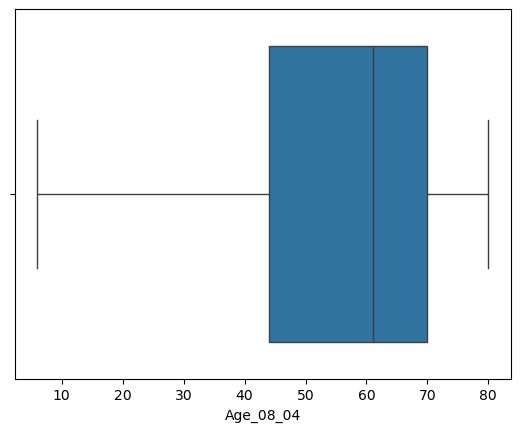

Column Name:  Mfg_Month


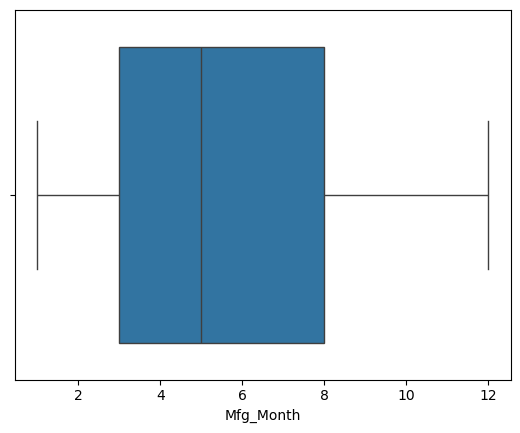

Column Name:  Mfg_Year


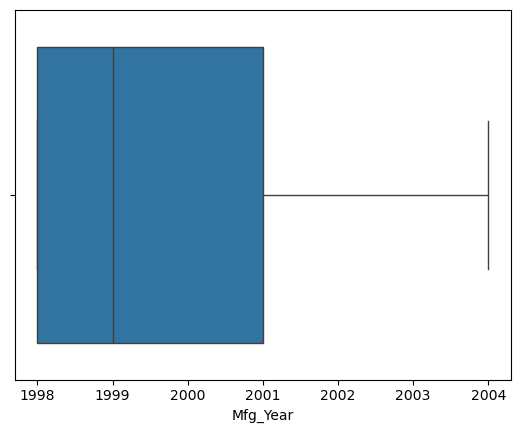

Column Name:  KM


C:\Users\DIBYAJIT\AppData\Local\Temp\ipykernel_17076\3855943007.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '63389.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  data.loc[outliers, column] = Median


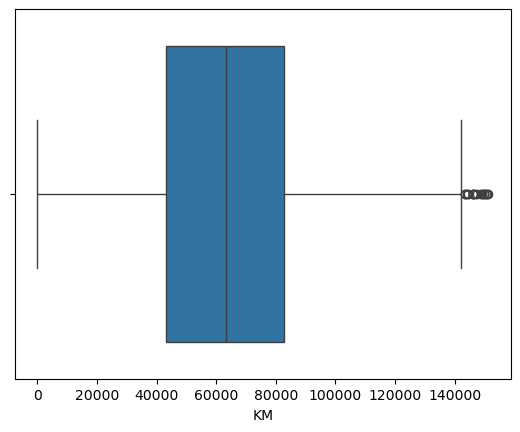

Column Name:  HP


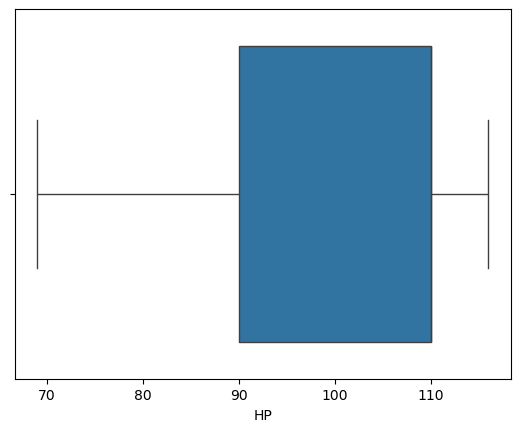

Column Name:  Met_Color


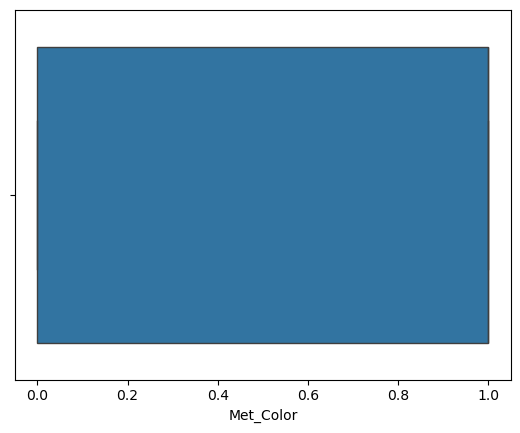

Column Name:  Automatic


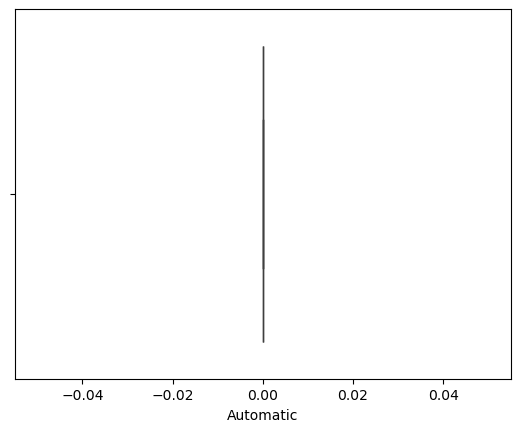

Column Name:  cc


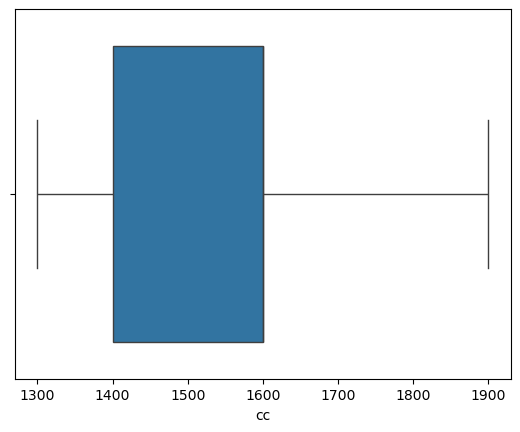

Column Name:  Doors


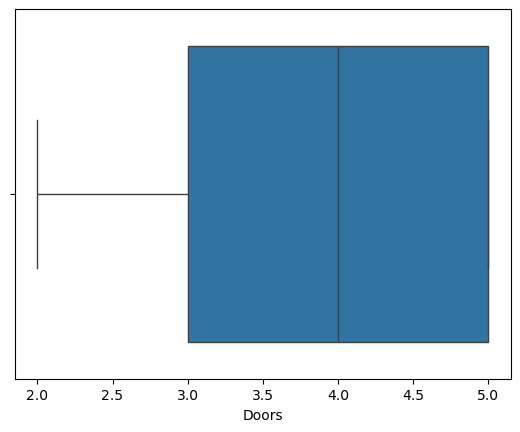

Column Name:  Cylinders


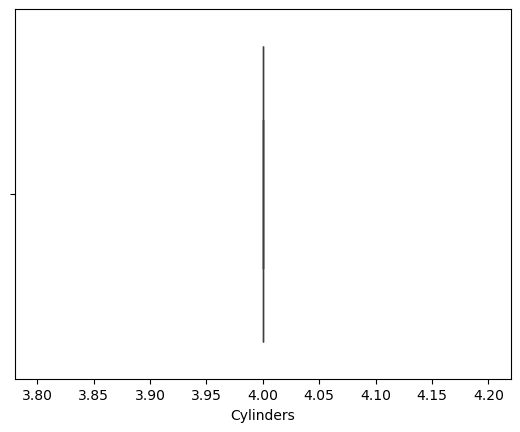

Column Name:  Gears


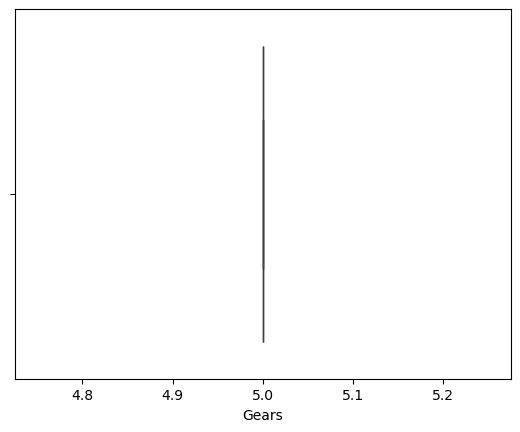

Column Name:  Quarterly_Tax


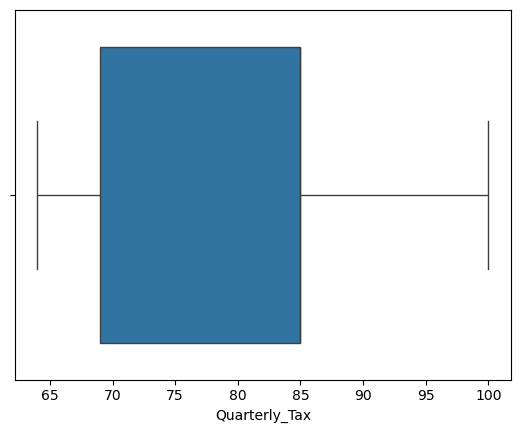

Column Name:  Weight


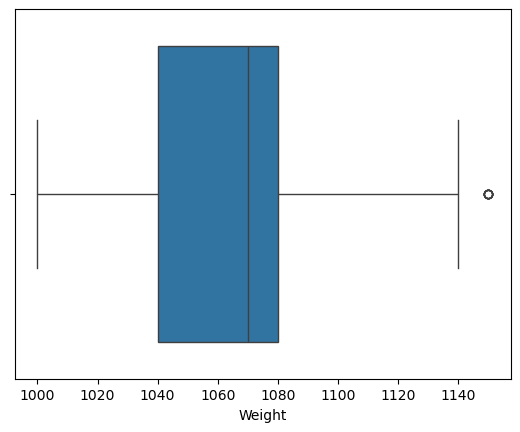

Column Name:  Mfr_Guarantee


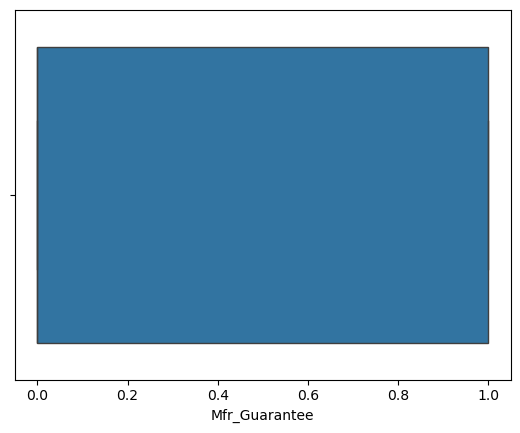

Column Name:  BOVAG_Guarantee


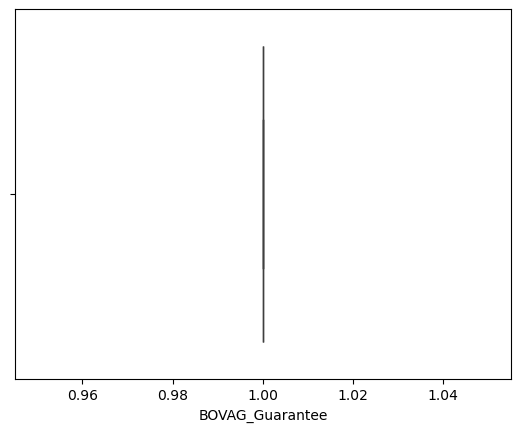

Column Name:  Guarantee_Period


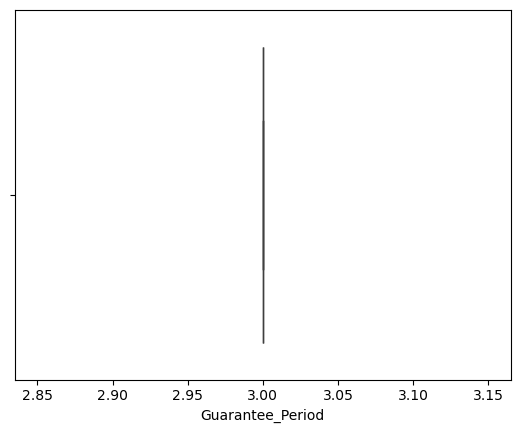

Column Name:  ABS


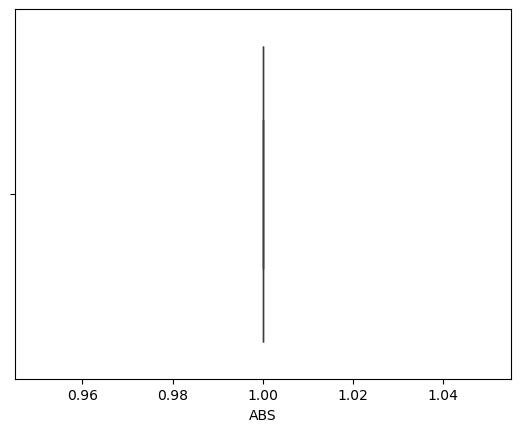

Column Name:  Airbag_1


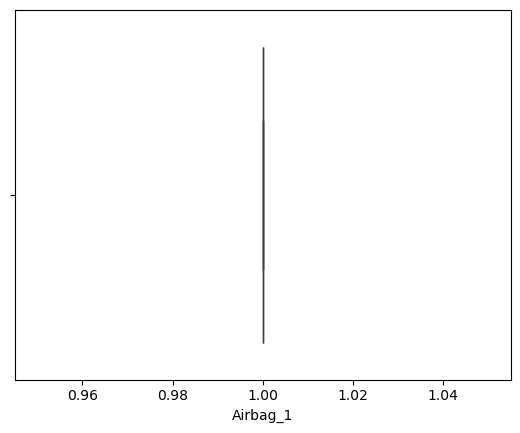

Column Name:  Airbag_2


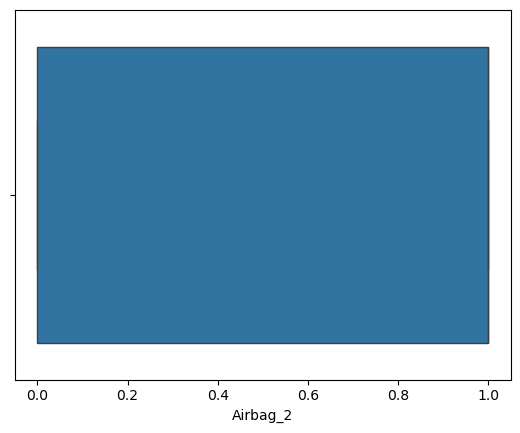

Column Name:  Airco


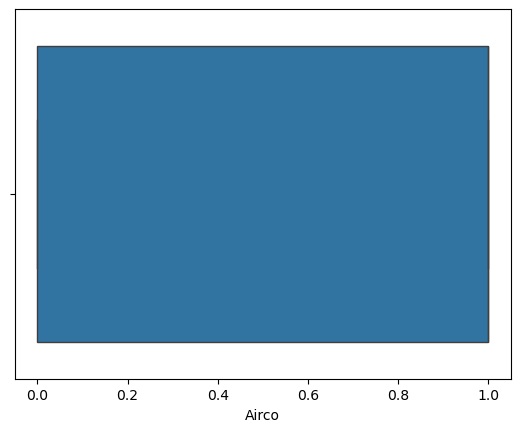

Column Name:  Automatic_airco


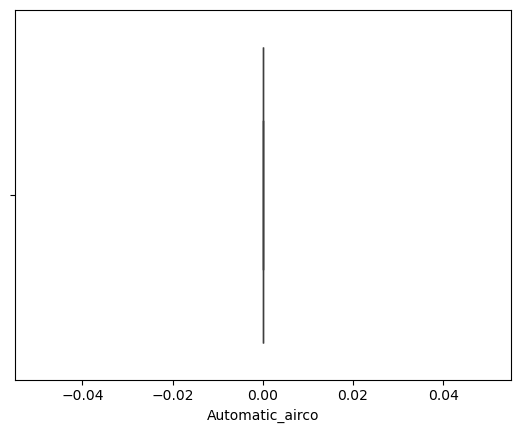

Column Name:  Boardcomputer


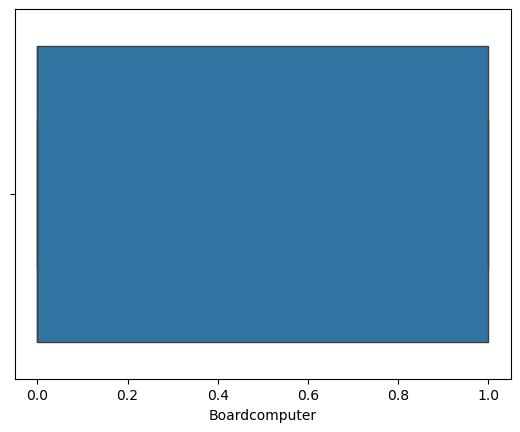

Column Name:  CD_Player


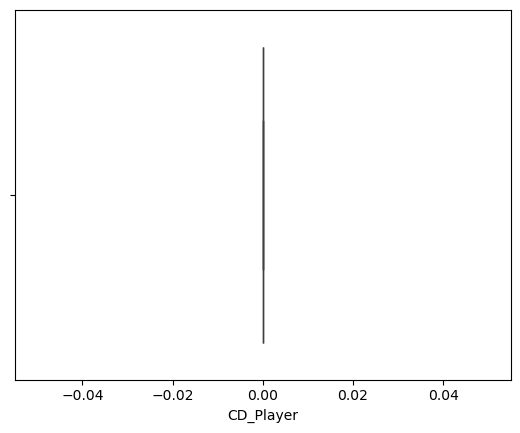

Column Name:  Central_Lock


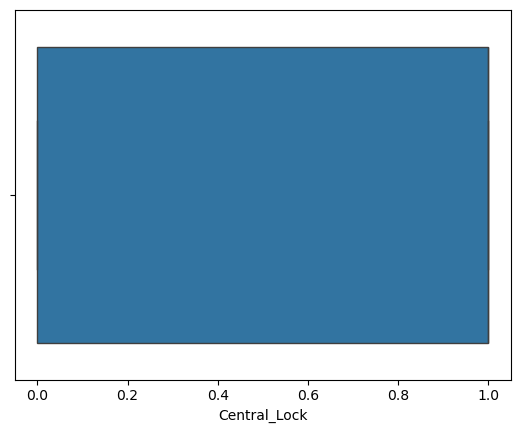

Column Name:  Powered_Windows


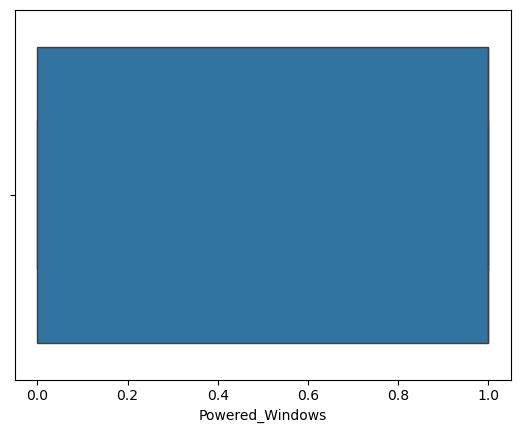

Column Name:  Power_Steering


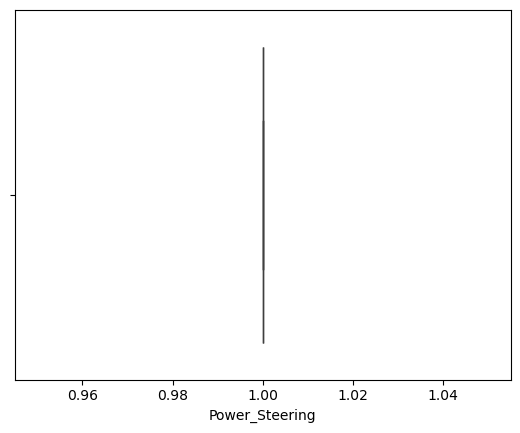

Column Name:  Radio


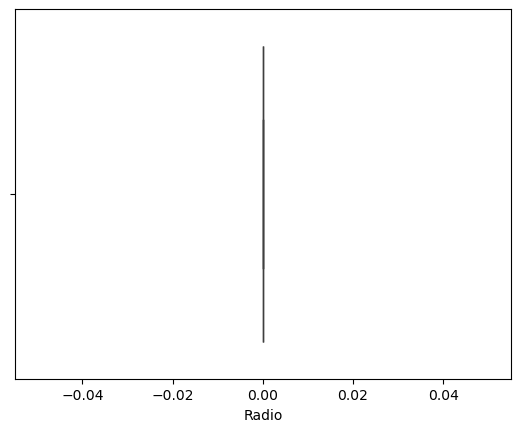

Column Name:  Mistlamps


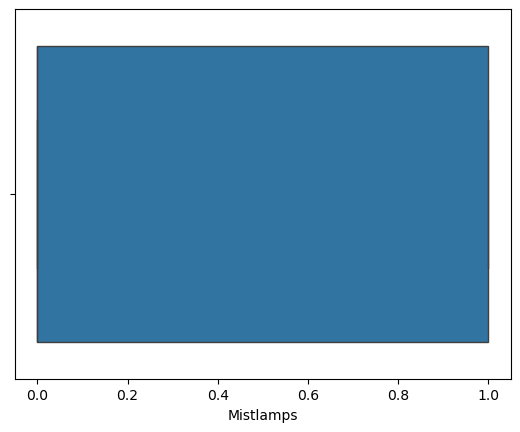

Column Name:  Sport_Model


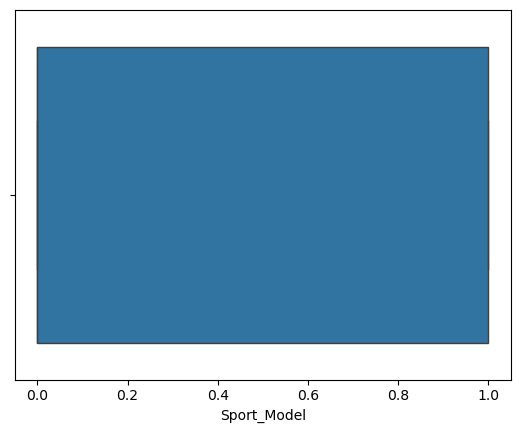

Column Name:  Backseat_Divider


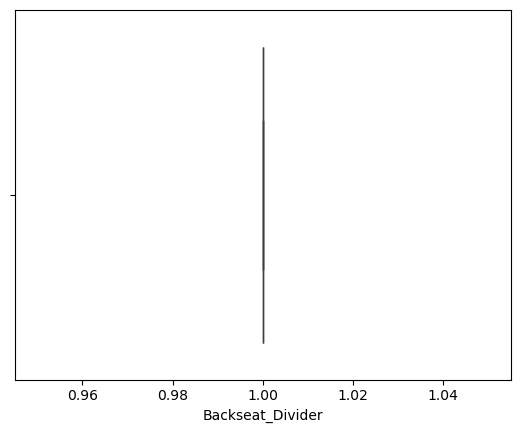

Column Name:  Metallic_Rim


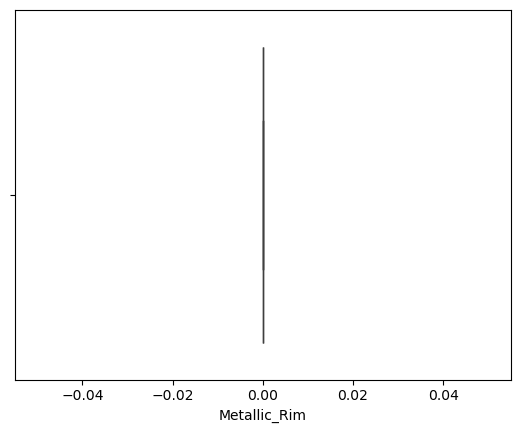

Column Name:  Radio_cassette


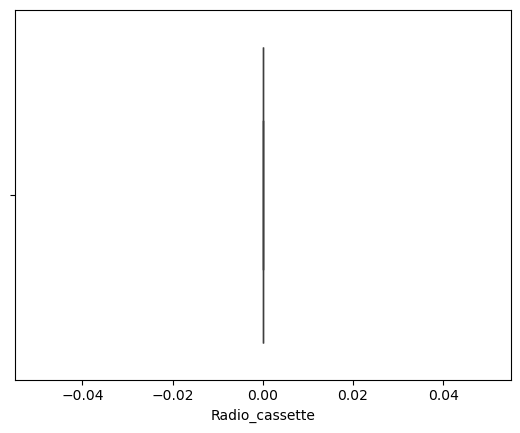

Column Name:  Tow_Bar


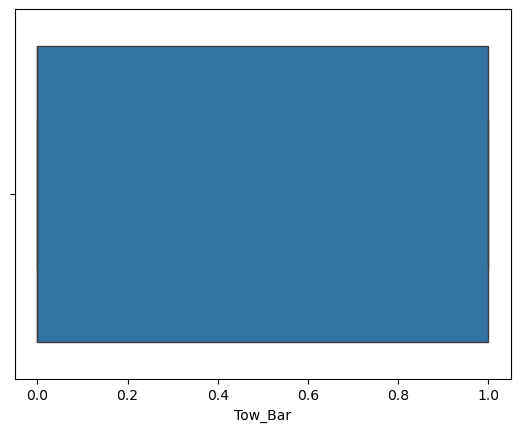

In [131]:
#looping through the numeric colms to impute the outliers of each columns
for i in num_cols:
    print ("Column Name: ", i)
    impute_outliers(data,i)
    

In [132]:
#train test split
data.shape

(1436, 38)

In [133]:
# Independent variables
X = data.drop(['Price', 'Id','Fuel_Type','Model','Color'], axis=1)

# Dependent variable
y = data['Price']

In [134]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.2, random_state = 42)

In [135]:
X_train.shape

(1148, 33)

In [136]:
reg = LinearRegression()   #### MUltiple Linear Regression

In [137]:
reg.fit(X_train,y_train)
pred_price = reg.predict(X_test)

In [138]:
acc = r2_score(y_test,pred_price)
print ("The MLR accuracy is : ",acc*100)

The MLR accuracy is :  84.44751532201715


In [143]:
r  = int (round (np.sqrt(data.shape[0]),0))
r

38

In [146]:
for i in (range (1, r+1)):
    knn = KNeighborsRegressor(n_neighbors=i) ## K Nearest Neighbours
    knn.fit(X_train,y_train)
    pred_profit2 = knn.predict (X_test)
    acc2 = r2_score (y_test,pred_profit2)
    err2 = 1 - acc
    print ("N number: ", i)
    print ("Accuracyr: ", acc2*100)
    print ("Error: " , err*100)

N number:  1
Accuracyr:  11.953977365369129
Error:  55.1551587911257
N number:  2
Accuracyr:  28.077954310894537
Error:  55.1551587911257
N number:  3
Accuracyr:  36.52683495003709
Error:  55.1551587911257
N number:  4
Accuracyr:  42.19265442998903
Error:  55.1551587911257
N number:  5
Accuracyr:  45.34786754371567
Error:  55.1551587911257
N number:  6
Accuracyr:  49.03484657647375
Error:  55.1551587911257
N number:  7
Accuracyr:  48.48085934744193
Error:  55.1551587911257
N number:  8
Accuracyr:  47.5605065175676
Error:  55.1551587911257
N number:  9
Accuracyr:  47.3338419765534
Error:  55.1551587911257
N number:  10
Accuracyr:  46.8710459276863
Error:  55.1551587911257
N number:  11
Accuracyr:  46.54167850949392
Error:  55.1551587911257
N number:  12
Accuracyr:  46.923777039872185
Error:  55.1551587911257
N number:  13
Accuracyr:  46.48711522089177
Error:  55.1551587911257
N number:  14
Accuracyr:  46.321652060340746
Error:  55.1551587911257
N number:  15
Accuracyr:  46.1914540175187

In [ ]:
# the accuracy of MLR is greater than that of any n value of KNN